In [37]:
#utils
import pandas as pd
import numpy as np
import contextlib
import os
import warnings

#visualization libraries
import matplotlib.pyplot as plt

#machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve

#models 
from models.AutoEncoder import Autoencoder
from models.ContractiveAutoEncoder import ContractiveAutoEncoder
from models.VariationalAutoencoder import VariationalAutoEncoder
from models.ALAD import ALAD


warnings.filterwarnings("ignore")

In [38]:
df = pd.read_csv('SimData.csv')
df = df.head(200)

In [39]:
target_feature = "isghost"
columns = df.drop(columns=target_feature).columns
#instantiate two more datasets one to contain the normal data
#and the other to hold the anomalous instances
train_normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

In [40]:
def get_normal_data(df):
    df = df.sample(frac=1)
    features = df.drop([target_feature], axis=1)
    label = df[target_feature]

    #the stratify parameter here is set to be "isghost" meaning that the 
    #proportions of ghost and normal tracks in both train and test datasets
    #will be kept the same...
    x_train, x_test, y_train, y_test = train_test_split(
        features, label, test_size=0.2, stratify=label
    )

    #remember that at least for the autoencoders we're gonna use just the 
    #normal instances during the training phase so we have to filter those in x_train
    train_index = y_train[y_train == 0].index
    train_normal_data = x_train.loc[train_index]

    return train_normal_data, x_train, y_train, x_test, y_test

In [41]:
train_normal_data, x_train, y_train, x_test, y_test = get_normal_data(df)

In [42]:
def standardize_normalize(train_x, normal_train_data, test_data):

    #creating a scaler and decing which columns to process
    normal_train_data = (normal_train_data - normal_train_data.mean()) / normal_train_data.std()
    train_x  =  (train_x - train_x.mean()) / train_x.std()
    test_data = (test_data - normal_train_data.mean()) / normal_train_data.std()

    #now moving the data to a fixed range of values 
    scaler = MinMaxScaler()

    normal_train_data = scaler.fit_transform(normal_train_data)
    train_x = scaler.fit_transform(train_x)
    test_data = scaler.fit_transform(test_data)

    return train_x, normal_train_data, test_data

In [43]:
x_train, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

In [44]:
INPUT_DIM = train_normal_data.shape[1]
ENCODING_DIM = 3
LEARNING_RATE = 0.003

In [45]:
def get_data():

    train_normal_data, _, _, x_test, y_test = get_normal_data(df)
    _, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

    return train_normal_data, x_test, y_test

In [46]:
def build_models():

    ae = Autoencoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
    cae = ContractiveAutoEncoder(INPUT_DIM, ENCODING_DIM, lambda_=0.01, learning_rate = LEARNING_RATE)
    vae = VariationalAutoEncoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)

    ae.build(input_shape=(train_normal_data.shape))
    cae.build(input_shape=(train_normal_data.shape))
    vae.build(input_shape=(train_normal_data.shape))
    
    return ae, cae, vae

In [47]:

def avgNestedLists(nested_vals):
    """
    Averages a 2-D array and returns a 1-D array of all of the columns
    averaged together, regardless of their dimensions.
    """
    output = []
    maximum = 0
    for lst in nested_vals:
        if len(lst) > maximum:
            maximum = len(lst)
    for index in range(maximum): # Go through each index of longest list
        temp = []
        for lst in nested_vals: # Go through each list
            if index < len(lst): # If not an index error
                temp.append(lst[index])
        output.append(np.nanmean(temp))
    return output

In [48]:
def transfer_weights(original_model, target_model, is_alad=False):


    #this is to check if the model is VAE
    #if so we want to skip the first layer 
    #for encoder and decoder, as it's an Input layer
    #not shared by the other networks
    
    target_encoder_layers = target_model.layers
    if target_model.name == "VAE":
        target_encoder_layers = target_model.layers[1:]

    target_decoder_layers = target_model.layers
    if target_model.name == "VAE":
        target_decoder_layers = target_model.layers[1:]

    #go throught the encoer weights 
    for source_layer, target_layer in zip(original_model.encoder.layers, target_encoder_layers):
        if target_layer.name != "bottleneck" and isinstance(target_layer, tf.keras.layers.InputLayer):
            target_layer.set_weights(source_layer.get_weights())

    #alad only has an encoder
    if not is_alad:
        #go throught the decoder layers 
        for source_layer, target_layer in zip(original_model.encoder.layers, target_decoder_layers):
            if target_layer.name != "final"  and isinstance(target_layer, tf.keras.layers.InputLayer):
                target_layer.set_weights(source_layer.get_weights())

    return target_model

In [49]:
import numpy as np
from sklearn.metrics import roc_curve, auc
from scipy import stats


def mean_and_confidence(model, threshold_function, alpha=0.95, iterations=5, transfer=False, epochs=5):
   

    #initialize all the containers for teh metrics to track
    list_fpr = []
    list_tpr = []
    list_auc = []

    #precision and recall will be used for 
    #the curve but also as general parameters 
    list_precision_curve = []
    list_recall_curve = []

    #classification metrics 
    list_accuracy = []
    list_precision = []
    list_recall = []
    list_f1 = []

    list_training_time = []


    flag = "tranfer" if transfer else ""

    model.save_weights('saved_weights/my_model' + flag + model.model_name)
        

    if transfer:
        ae = Autoencoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
        ae.build(input_shape=(train_normal_data.shape))
        ae.save_weights('saved_weights/my_model' + flag + ae.model_name)
    

    # Perform 100 iterations
    for _ in range(iterations):

        x_train, x_test, y_test = get_data()

        if transfer:
            
            history_ae, training_time_ae = ae.train(x_train, epochs=200, batch_size=30, validation_split=0.2)
            #tranfer_learning here
            model = transfer_weights(ae, model)

        history, training_time = model.train(x_train, epochs=epochs, batch_size=30, validation_split=0.2)
        ###time each model 
        threshold = threshold_function(x_train, x_test, y_test)
        predictions = model.find_anomalies(x_test, threshold)
        accuracy, precision, recall, f1 = model.classification_metrics(y_test, predictions)

        #re-set all the trainable variables of the model
        model.load_weights('saved_weights/my_model' + flag + model.model_name)
        
        fpr_ae, tpr_ae, _ = roc_curve(y_test, predictions)
        auc_ae = auc(fpr_ae, tpr_ae)
        list_fpr.append(fpr_ae)
        list_tpr.append(tpr_ae)
        

        precision_curve, recall_curve, _ = precision_recall_curve(y_test, predictions)
        list_precision_curve.append(precision_curve)
        list_recall_curve.append(recall_curve)


        list_accuracy.append(accuracy)
        list_precision.append(precision)
        list_recall.append(recall)
        list_f1.append(f1)
        list_training_time.append(training_time)
        list_auc.append(auc_ae)

    #roc_curve can return different sized arrays
    #this means that ther needs to be a custom function
    #to compute the mean 
    avg_fpr = avgNestedLists(list_fpr)
    avg_tpr = avgNestedLists(list_tpr)
    avg_precision_curve = avgNestedLists(list_precision_curve)
    avg_recall_curve = avgNestedLists(list_recall_curve)
    avg_acc = np.mean(list_accuracy)
    avg_rec = np.mean(list_recall)
    avg_pre = np.mean(list_precision)
    avg_f1 = np.mean(list_f1)
    avg_time = np.mean(list_training_time)
    avg_auc = np.mean(list_auc)


    #standard deviations
    accuracy_std = np.std(list_accuracy)
    precision_std = np.std(list_precision)
    recall_std = np.std(list_recall)
    f1_std = np.std(list_f1)
    training_time_std = np.std(list_training_time)
    auc_std = np.std(list_auc)

    #how to take the "mean curve"  
    interval_acc = stats.t.interval(alpha=alpha, loc=np.mean(list_accuracy), df=len(list_accuracy)-1, scale=stats.sem(list_accuracy))
    interval_rec = stats.t.interval(alpha=alpha, loc=np.mean(list_recall), df=len(list_recall)-1, scale=stats.sem(list_recall))
    interval_pre = stats.t.interval(alpha=alpha, loc=np.mean(list_precision), df=len(list_precision)-1, scale=stats.sem(list_precision))
    interval_f1 = stats.t.interval(alpha=alpha, loc=np.mean(list_f1), df=len(list_f1)-1, scale=stats.sem(list_f1))
    interval_time = stats.t.interval(alpha=alpha, loc=np.mean(list_training_time), df=len(list_training_time)-1, scale=stats.sem(list_training_time))
    interval_auc = stats.t.interval(alpha=alpha, loc=np.mean(list_auc), df=len(list_auc)-1, scale=stats.sem(list_auc))

    plt.plot(avg_fpr, avg_tpr)
    plt.plot(avg_fpr, avg_tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % avg_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + model.model_name)
    plt.text(1.05, 0.5, "With Transfer Learning", fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.legend(loc="lower right")
    plt.savefig('images/Average ROC Transfer Learning' + model.model_name)
    plt.close()

    plt.plot(avg_precision_curve, avg_recall_curve)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.text(1.05, 0.5, "With Transfer Learning", fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.savefig('images/Average Precision Recall Transfer learning' + model.model_name)
    plt.close()


    averages = {
        "Average FPR": avg_fpr,
        "Average TPR": avg_tpr,
        "Average precision curve": avg_precision_curve,
        "Average recall curve": avg_recall_curve,
        "Average accuracy": avg_acc,
        "Average recall": avg_rec,
        "Average precision": avg_pre,
        "Average F-1": avg_f1,
        "Average training time": avg_time,
        "Average AUC": avg_auc,
        }
    

    sigmas = {
        "STD accuracy": accuracy_std,
        "STD recall": recall_std,
        "STD precision": precision_std,
        "STD F-1": f1_std,
        "STD training time": training_time_std,
        "STD AUC": auc_std,
    }

    
    intervals = {
        "Interval accuracy": interval_acc,
        "Interval recall": interval_rec,
        "Interval precision": interval_pre,
        "Interval F-1": interval_f1,
        "Interval training time": interval_time,
        "Interval AUC": interval_auc,
        }
    
    return averages, intervals, sigmas

In [50]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    ae, cae, vae = build_models()

    averages_ae, intervals_ae, _ = mean_and_confidence(ae, ae.find_best_deviations_threshold, alpha=0.95)
    averages_cae, intervals_cae, _ = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95)
    averages_vae, intervals_vae, _ = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95)

In [51]:
def roc_curve_models(avg_ae=None, avg_cae=None, avg_vae=None, fun_name=None, avg_alad=None):

    if avg_ae is not None:
        fpr_ae = avg_ae["Average FPR"]
        tpr_ae = avg_ae["Average TPR"]
        auc_ae = avg_ae["Average AUC"]

    fpr_cae = avg_cae["Average FPR"]
    tpr_cae = avg_cae["Average TPR"]
    fpr_vae = avg_vae["Average FPR"]
    tpr_vae = avg_vae["Average TPR"]

    
    auc_cae = avg_cae["Average AUC"]
    auc_vae = avg_vae["Average AUC"]
    #auc_alad = averages_alad["Average AUC"]

    """"
    fpr_alad = avg_alad["Average FPR"]
    tpr_alad = avg_alad["Average TPR"]
    """


    x = np.linspace(0, 1, 10)

    # Compute y values (y = x)
    y = x

    # Plot the diagonal dotted line
    plt.plot(x, y, linestyle=':', color='purple')
    
    if avg_ae is not None:
        plt.plot(fpr_ae, tpr_ae, label='AE (AUC = {})'.format(round(auc_ae, 2)))

    plt.plot(fpr_cae, tpr_cae, label='CAE (AUC = {})'.format(round(auc_cae, 2)))
    plt.plot(fpr_vae, tpr_vae, label='VAE (AUC = {})'.format(round(auc_vae, 2)))
    """""
    plt.plot(fpr_alad, tpr_alad, label='ALAD (AUC = {auc_alad:.2f})')"""

    # Adding labels and legends
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.text(1.05, 0.5, fun_name, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.legend()
    plt.savefig('images/All models ROC')

    # Display the plot
    plt.show()

In [52]:
def pr_models(avg_ae=None, avg_cae=None, avg_vae=None, fun_name=None, avg_alad=None):    
    #plot all the precision-recall losses together

    if avg_ae is not None:
        precision_ae, recall_ae, = avg_ae["Average precision curve"], avg_ae["Average recall curve"]

    precision_cae, recall_cae, = avg_cae["Average precision curve"], avg_cae["Average recall curve"]
    precision_vae, recall_vae, = avg_vae["Average precision curve"], avg_vae["Average recall curve"]



    # plot the precision-recall curve
    if avg_ae is not None:
        plt.plot(recall_ae, precision_ae, color='blue', label='AE')
        
    plt.plot(recall_cae, precision_cae, color='red', label='CAE')
    plt.plot(recall_vae, precision_vae, color='green', label='VAE')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.text(1.05, 0.5, fun_name, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.savefig('images/All models P-R')
    plt.show()

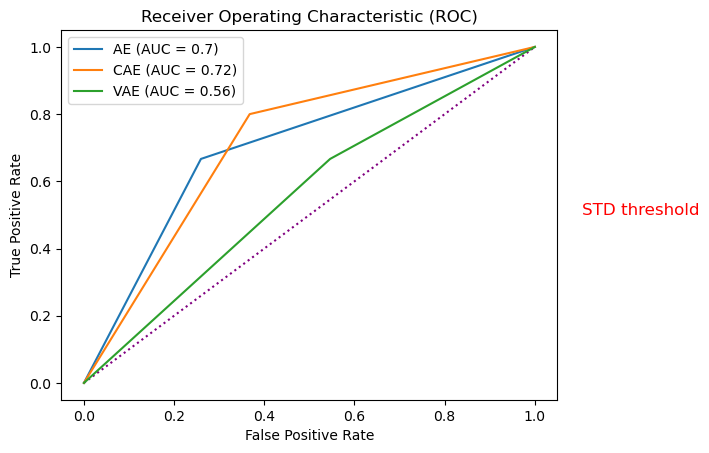

In [53]:
roc_curve_models(avg_ae=averages_ae, avg_cae=averages_cae, avg_vae=averages_vae, fun_name="STD threshold")

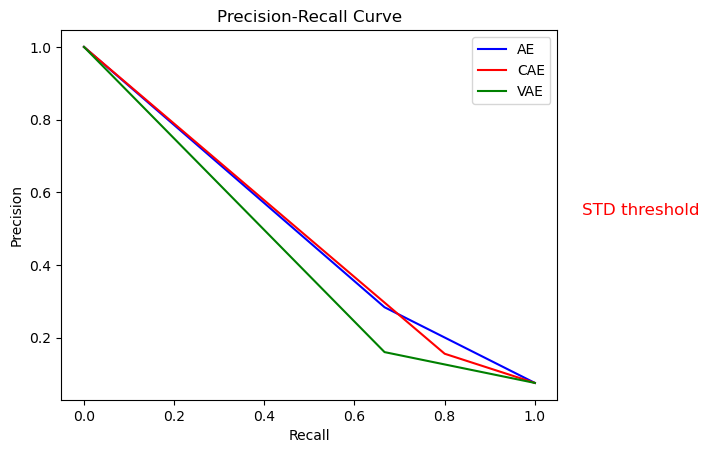

In [54]:
pr_models(avg_ae=averages_ae, avg_cae=averages_cae, avg_vae=averages_vae, fun_name="STD threshold")

In [55]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    ae, cae, vae = build_models()

    #test different threshold function 
    averages_ae, intervals_ae, _ = mean_and_confidence(ae, ae.find_best_percentile_threshold, alpha=0.95, iterations=5, transfer=False)
    averages_cae, intervals_cae, _ = mean_and_confidence(cae, cae.find_best_percentile_threshold, alpha=0.95, iterations=5, transfer=False)
    averages_vae, intervals_vae, _ = mean_and_confidence(vae, vae.find_best_percentile_threshold, alpha=0.95, iterations=5, transfer=False)

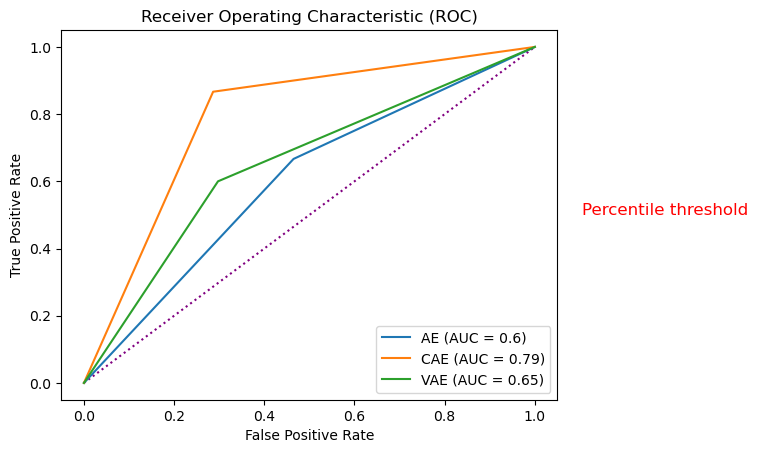

In [56]:
roc_curve_models(avg_ae=averages_ae, avg_cae=averages_cae, avg_vae=averages_vae, fun_name="Percentile threshold")

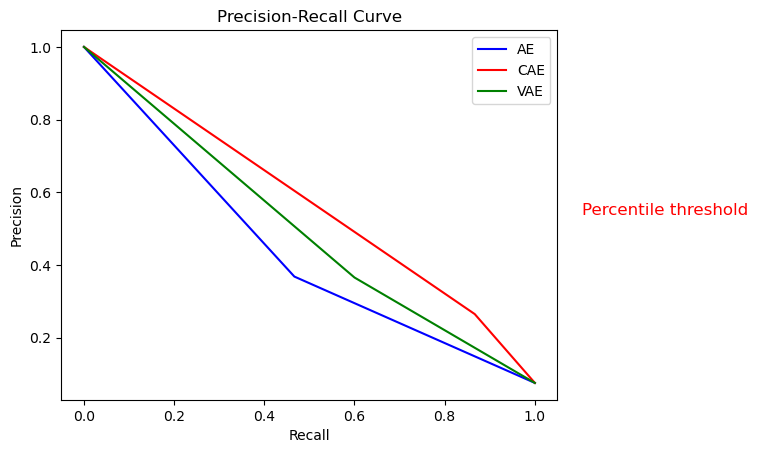

In [57]:
pr_models(avg_ae=averages_ae, avg_cae=averages_cae, avg_vae=averages_vae, fun_name="Percentile threshold")

It seems from these experiments that the what works best to determine the threshold for anomalies is indeed the "standard deviations method". The results from it infact dominate the ones from the "percentile method". 

# Transfer learning

Make only the AE learn by itself... Then compare the results of the transfer-learned models aginst the ones collected from training each on its own. 

In [58]:
# reinstantiate the models 

ae = Autoencoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
cae = ContractiveAutoEncoder(INPUT_DIM, ENCODING_DIM, lambda_=0.01, learning_rate = LEARNING_RATE)
vae = VariationalAutoEncoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
ae.build(input_shape=(train_normal_data.shape))
cae.build(input_shape=(train_normal_data.shape))
vae.build(input_shape=(train_normal_data.shape))

In [59]:
ae.train(train_normal_data, epochs=200, batch_size=64, validation_split=0.2)

Epoch 1/200
2/2 [==============================] - 2s 388ms/step - loss: 0.0937 - val_loss: 0.0838
Epoch 2/200
2/2 [==============================] - 0s 51ms/step - loss: 0.0782 - val_loss: 0.0447
Epoch 3/200
2/2 [==============================] - 0s 60ms/step - loss: 0.0371 - val_loss: 0.0319
Epoch 4/200
2/2 [==============================] - 0s 57ms/step - loss: 0.0298 - val_loss: 0.0359
Epoch 5/200
2/2 [==============================] - 0s 63ms/step - loss: 0.0296 - val_loss: 0.0278
Epoch 6/200
2/2 [==============================] - 0s 67ms/step - loss: 0.0227 - val_loss: 0.0231
Epoch 7/200
2/2 [==============================] - 0s 59ms/step - loss: 0.0212 - val_loss: 0.0247
Epoch 8/200
2/2 [==============================] - 0s 63ms/step - loss: 0.0228 - val_loss: 0.0242
Epoch 9/200
2/2 [==============================] - 0s 80ms/step - loss: 0.0222 - val_loss: 0.0233
Epoch 10/200
2/2 [==============================] - 0s 76ms/step - loss: 0.0205 - val_loss: 0.0231
Epoch 11/200
2/2 [

(<keras.callbacks.History at 0x2032916e9b0>, 19.77865219116211)

In [60]:
#transfer the weights learned by the autoencoder
cae = transfer_weights(ae, cae)
vae = transfer_weights(ae, vae)

In [61]:
#refine the training. this is especially importatn for the VAE, that also has a lambda layer
#that couldn't be inizialiazed with the AE weights
cae.train(train_normal_data, epochs=5, batch_size=64, validation_split=0.2)
vae.train(train_normal_data, epochs=10, batch_size=64, validation_split=0.2)

Step: 0, Train Loss: 0.09256860613822937, Val Loss: 0.08654454350471497
Step: 0, Train Loss: 0.07656701654195786, Val Loss: 0.05513879284262657
Step: 0, Train Loss: 0.037443019449710846, Val Loss: 0.02969915233552456
Step: 0, Train Loss: 0.03894060477614403, Val Loss: 0.02381831221282482
Step: 0, Train Loss: 0.02676883526146412, Val Loss: 0.023099172860383987
Epoch 1/10
2/2 [==============================] - 2s 356ms/step - loss: 0.6816 - val_total_loss: 0.0000e+00
Epoch 2/10
2/2 [==============================] - 0s 61ms/step - loss: 0.6082 - val_total_loss: 0.0000e+00
Epoch 3/10
2/2 [==============================] - 0s 51ms/step - loss: 0.5633 - val_total_loss: 0.0000e+00
Epoch 4/10
2/2 [==============================] - 0s 49ms/step - loss: 0.5470 - val_total_loss: 0.0000e+00
Epoch 5/10
2/2 [==============================] - 0s 87ms/step - loss: 0.5372 - val_total_loss: 0.0000e+00
Epoch 6/10
2/2 [==============================] - 0s 53ms/step - loss: 0.5294 - val_total_loss: 0.0000

(<keras.callbacks.History at 0x203697307c0>, 2.9597694873809814)

In [62]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    ae, cae, vae = build_models()


    averages_cae, intervals_cae, sigmas_cae = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95, transfer=True)
    averages_vae, intervals_vae, sigmas_vae = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95, transfer=True)

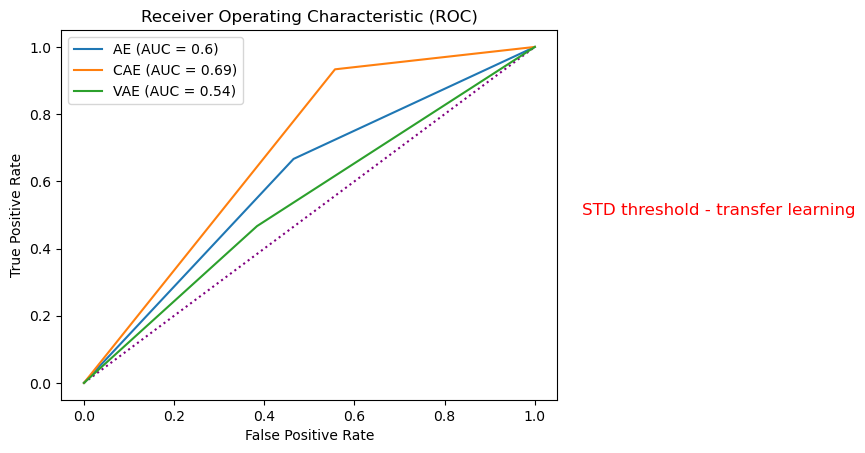

In [63]:
roc_curve_models(averages_ae, averages_cae, averages_vae, "STD threshold - transfer learning")

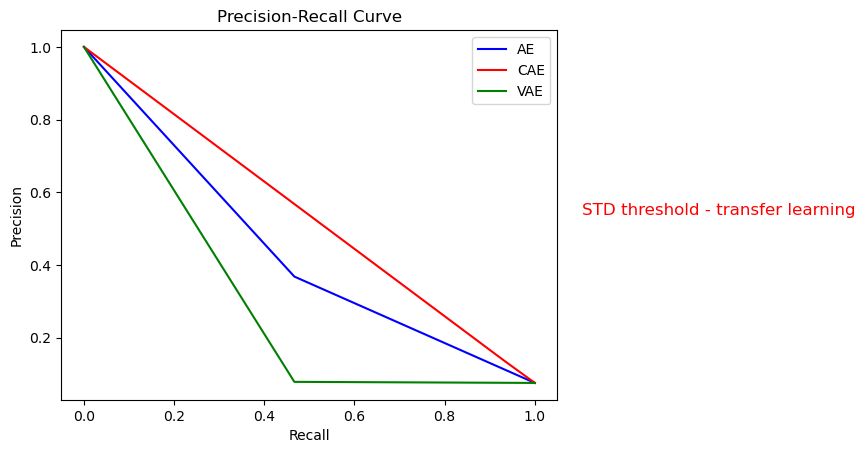

In [64]:
pr_models(averages_ae, averages_cae, averages_vae, "STD threshold - transfer learning")

Run mean_and_confidence with 200 epochs for cae, vae and then check if the averages haev significant difference to the ones found with the transfer learning method. 

In [65]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):
    averages_cae_no_transfer, intervals_cae_no_transfer, sigmas_cae_no_trasnfer = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95, epochs=200)
    averages_vae_no_transfer, intervals_vae_no_transfer, sigmas_vae_no_trasnfer = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95, epochs=200)

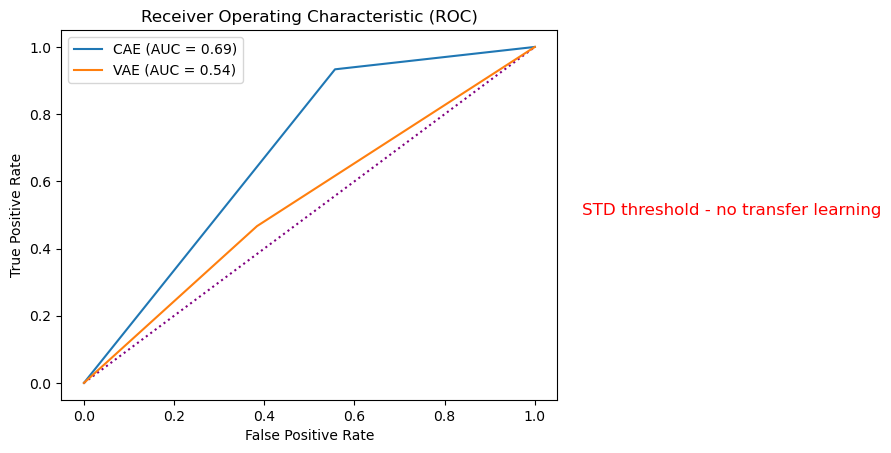

In [66]:
roc_curve_models(avg_cae=averages_cae, avg_vae=averages_vae, fun_name="STD threshold - no transfer learning")

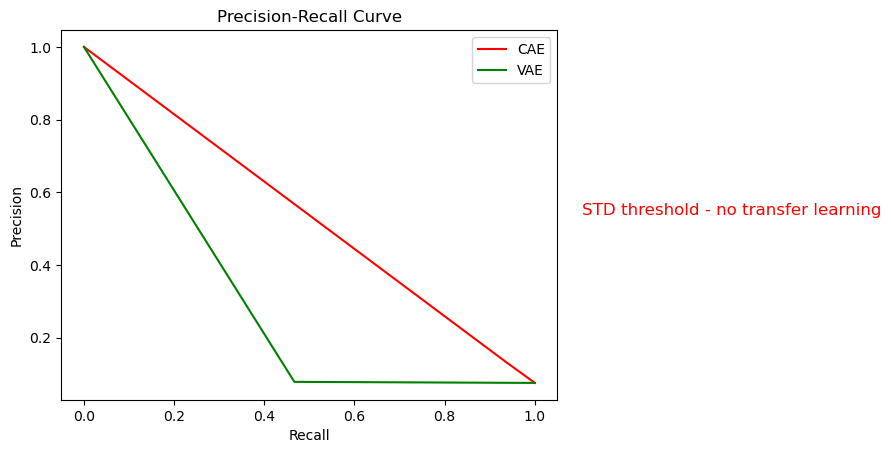

In [67]:
pr_models(avg_cae=averages_cae, avg_vae=averages_vae, fun_name="STD threshold - no transfer learning")

Run mean_and_confidence with 200 epochs for cae, vae and then check if the averages haev significant difference to teh ones found with the transfer learning method. 

# TO USE Z-TEST THE DATA HAS TO BE NORMALLY DISTRIBUTED AND POPULATION > 30

Finally take the difference between teh different average values using the z-score formula. The null hypothesis here is that there is no difference between the two means. The alternative hypothesis will instead be that mean_1 > mean_2

In [68]:
from scipy.stats import norm

#averages_cae = pd.DataFrame.from_dict(averages_cae, orient='index')
"""averages_cae_no_transfer = pd.DataFrame.from_dict(averages_cae_no_transfer, orient='index', columns=['Average'])
averages_vae = pd.DataFrame.from_dict(averages_vae, orient='index', columns=['Average'])
averages_vae_no_transfer = pd.DataFrame.from_dict(averages_vae_no_transfer, orient='index', columns=['Average'])

"""


critical = 1.645
averages_cae = dict(list(averages_cae.items())[-6:])
keys = list(averages_cae.keys())
means = pd.DataFrame(averages_cae.values(), columns=["Avg transfer"])
std = pd.DataFrame(sigmas_cae.values(), columns=["Sigma transfer"])

averages_cae_no_transfer = dict(list(averages_cae_no_transfer.items())[-6:])
means_no = pd.DataFrame(averages_cae_no_transfer.values(), columns=["Avg no transfer"])
std_no = pd.DataFrame(sigmas_cae_no_trasnfer.values(), columns=["Sigma no transfer"])

#n is equal to the iterations of the mean_confidence method
n = 5
numer = means['Avg transfer'] - means_no['Avg no transfer']
denom = np.sqrt((std['Sigma transfer']**2 / n) + (std_no['Sigma no transfer']**2 / n))
z_score = numer / denom
p_value = 2 * (1 - norm.cdf(np.abs(z_score)))

df = pd.DataFrame({'z-score': z_score, 'p-value': p_value})
df['Decision'] = ['Reject Null' if z > critical else "Don't reject null" for z in df['z-score']]
df.index = ["Accuracy", "Recall", "Precision", "F1", "Training time", "AUC"]
df.name = "CAE values"
df.head()

,z-score,p-value,Decision
Accuracy,1.077215,0.281384,Don't reject null
Recall,1.581139,0.113846,Don't reject null
Precision,2.901985,0.003708,Reject Null
F1,3.174822,0.001499,Reject Null
Training time,-145.114508,0.000000,Don't reject null


In [69]:
critical = 1.645
averages_vae = dict(list(averages_vae.items())[-6:])
keys = list(averages_vae.keys())
means = pd.DataFrame(averages_vae.values(), columns=["Avg transfer"])
std = pd.DataFrame(sigmas_vae.values(), columns=["Sigma transfer"])

averages_vae_no_transfer = dict(list(averages_vae_no_transfer.items())[-6:])
means_no = pd.DataFrame(averages_vae_no_transfer.values(), columns=["Avg no transfer"])
std_no = pd.DataFrame(sigmas_vae_no_trasnfer.values(), columns=["Sigma no transfer"])

#n is equal to the iterations of the mean_confidence method
n = 5
numer = means['Avg transfer'] - means_no['Avg no transfer']
denom = np.sqrt((std['Sigma transfer']**2 / n) + (std_no['Sigma no transfer']**2 / n))
z_score = numer / denom
p_value = 2 * (1 - norm.cdf(np.abs(z_score)))

df = pd.DataFrame({'z-score': z_score, 'p-value': p_value})
df['Decision'] = ['Reject Null' if z > critical else "Don't reject null" for z in df['z-score']]
df.index = ["Accuracy", "Recall", "Precision", "F1", "Training time", "AUC"]
df.name = "VAE values"
df.head()

,z-score,p-value,Decision
Accuracy,1.311578,0.189662,Don't reject null
Recall,-2.857738,0.004267,Don't reject null
Precision,-1.791855,0.073156,Don't reject null
F1,-2.073583,0.038118,Don't reject null
Training time,-23.034481,0.000000,Don't reject null
